## Model Evaluation and Business Uplift Simulation

### Objective

This notebook evaluates the business impact of CLV-based targeting through uplift simulation. While CLV models provide estimates of future customer value, their practical usefulness depends on how well they support improved decision-making.

The analysis simulates a common marketing use case: targeting the top X% of customers ranked by predicted CLV and comparing revenue captured against random selection of the same size. This approach reflects how CLV models are operationalized in strategy planning and budget allocation.

### Evaluation Scope

This notebook evaluates the **ML 6-month CLV model** using its test set predictions. The probabilistic 12-month CLV is not included in this simulation because it was calibrated on the full observation period and would require a different evaluation framework.

### Important Caveat

The uplift curve shows **in-sample performance** - the model was trained on data from the same period being evaluated. Results should be interpreted as model capability rather than expected field performance. A rigorous out-of-sample evaluation would require a longer observation window with multiple cutoff points.

### Output

A consolidated uplift simulation dataset quantifying revenue capture across targeting thresholds, exported for downstream analysis and Power BI reporting.

## Load 6-Month ML CLV Predictions with Actuals

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Color palette
COLOR_PRIMARY = "#2E4057"      # Dark slate blue
COLOR_SECONDARY = "#E67E22"    # Burnt orange
COLOR_ACCENT = "#27AE60"       # Forest green
COLOR_GRID = "#D5D8DC"         # Light grey
COLOR_TEXT = "#2C3E50"         # Dark grey-blue
COLOR_BASELINE = "#95A5A6"     # Medium grey
COLOR_HIGHLIGHT = "#C0392B"    # Deep red for emphasis

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COLOR_TEXT,
    "axes.labelcolor": COLOR_TEXT,
    "text.color": COLOR_TEXT,
    "xtick.color": COLOR_TEXT,
    "ytick.color": COLOR_TEXT,
    "grid.color": COLOR_GRID,
    "grid.alpha": 0.4,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Load ML CLV predictions with actuals
ml_clv6_path = "/kaggle/input/customers-clv-ml-6m/customers_clv_ml_6m.csv"
ml_clv6 = pd.read_csv(ml_clv6_path)

print(f"ML CLV dataset: {ml_clv6.shape}")
print(f"Customers: {len(ml_clv6):,}")
print(f"Total actual 6-month revenue: £{ml_clv6['Actual_Target6M'].sum():,.2f}")

ml_clv6.head()

ML CLV dataset: (4932, 12)
Customers: 4,932
Total actual 6-month revenue: £4,244,762.10


,CustomerID,CLV_6m_pred,Actual_Target6M,Frequency,Monetary,RecencyDays,TenureDays,CustomerAgeDays,AvgOrderValue,AvgItemsPerOrder,PurchaseRateMonthly,Country
0,12346.0,207.635029,0.00,11,372.86,345,196,542,33.896364,6.363636,1.675127,United Kingdom
1,12347.0,1326.627937,2486.57,4,3146.75,63,157,220,786.687500,486.250000,0.759494,Iceland
2,12348.0,635.599597,310.00,4,1709.40,65,189,254,427.350000,624.250000,0.631579,Finland
3,12349.0,812.974905,1457.55,2,2221.14,224,181,405,1110.570000,495.500000,0.329670,Italy
4,12350.0,467.615225,0.00,1,334.40,126,0,126,334.400000,197.000000,1.000000,Norway


## Uplift Curve: Methodology

The uplift curve ranks customers by predicted 6-month CLV and measures cumulative actual revenue captured as progressively larger fractions are targeted. This mirrors strategic decisions where budget or capacity constraints limit how many customers can be engaged.

**Key thresholds evaluated:**
- Top 1% (highest-value customers, premium targeting).
- Top 5% (concentrated campaign).
- Top 10% (focused campaign).
- Top 20% (broad but still selective).

**Baseline:** Random targeting, where X% of customers capture X% of revenue (diagonal line).

**Uplift interpretation:** The gap between the model curve and baseline represents incremental revenue gained by using CLV to guide targeting.

In [ ]:
# Prepare uplift analysis dataset
df = ml_clv6.copy()
df = df.sort_values("CLV_6m_pred", ascending = False).reset_index(drop = True)

# Calculate cumulative revenue capture
df["cum_actual_rev"] = df["Actual_Target6M"].cumsum()
total_actual_revenue = df["Actual_Target6M"].sum()
df["cum_actual_rev_pct"] = df["cum_actual_rev"] / total_actual_revenue
df["customers_pct"] = (np.arange(len(df)) + 1) / len(df)

# Calculate uplift metrics at key thresholds
thresholds = [0.01, 0.05, 0.10, 0.20]
print("\nUplift Summary:")
print(f"{'Target':<10} {'Revenue Capture':<20} {'Lift':<10} {'Customers':<12}")
print("-" * 52)

for p in thresholds:
    idx = max(int(len(df) * p) - 1, 0)
    rev_captured = df.loc[idx, "cum_actual_rev_pct"]
    lift = rev_captured / p
    n_customers = idx + 1
    print(f"Top {p:.0%} {'':<4} {rev_captured:.1%} {'':<10} {lift:.1f}x {'':<6} {n_customers:,}")


Uplift Summary:
Target     Revenue Capture      Lift       Customers   
----------------------------------------------------
Top 1%      32.7%            32.7x        49
Top 5%      52.4%            10.5x        246
Top 10%      64.9%            6.5x        493
Top 20%      79.2%            4.0x        986


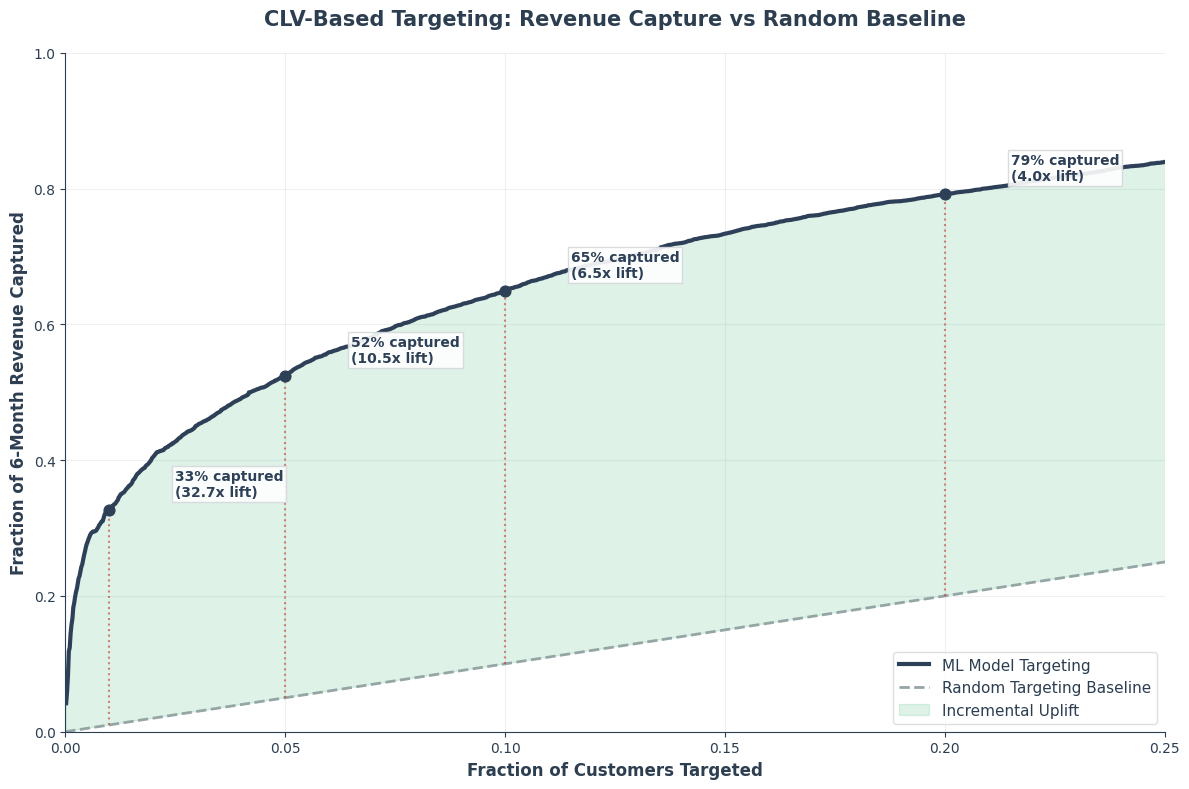

In [3]:
# Uplift curve visualization
fig, ax = plt.subplots(figsize = (12, 8))

# Model curve
ax.plot(df["customers_pct"], df["cum_actual_rev_pct"], 
        linewidth = 3, 
        color = COLOR_PRIMARY, 
        label = "ML Model Targeting",
        zorder = 3)

# Baseline
ax.plot([0, 1], [0, 1], 
        linestyle = '--', 
        color = COLOR_BASELINE, 
        linewidth = 2,
        label = "Random Targeting Baseline",
        zorder = 2)

# Shade incremental uplift area
ax.fill_between(df["customers_pct"], 
                df["customers_pct"], 
                df["cum_actual_rev_pct"], 
                color = COLOR_ACCENT, 
                alpha = 0.15, 
                label = "Incremental Uplift",
                zorder = 1)

# Highlight key thresholds
for p in thresholds:
    idx = max(int(len(df) * p) - 1, 0)
    rev_captured = df.loc[idx, "cum_actual_rev_pct"]
    lift = rev_captured / p
    
    # Plot model point
    ax.scatter(p, rev_captured, color = COLOR_PRIMARY, s = 60, zorder = 4)
    
    # Vertical line to baseline
    ax.vlines(x = p, ymin = p, ymax = rev_captured, 
             color = COLOR_HIGHLIGHT, linestyle = ':', alpha = 0.6, linewidth = 1.5)
    
    # Annotation
    ax.annotate(f"{rev_captured:.0%} captured\n({lift:.1f}x lift)", 
                xy = (p, rev_captured), 
                xytext = (p + 0.015, rev_captured + 0.02),
                fontsize = 10, 
                fontweight = 'bold', 
                color = COLOR_PRIMARY,
                bbox = dict(facecolor = 'white', edgecolor = COLOR_GRID, alpha = 0.9, pad = 2))

ax.set_title("CLV-Based Targeting: Revenue Capture vs Random Baseline", 
             fontsize = 15, fontweight = 'bold', pad = 20)
ax.set_xlabel("Fraction of Customers Targeted", fontsize = 12, fontweight = 'semibold')
ax.set_ylabel("Fraction of 6-Month Revenue Captured", fontsize = 12, fontweight = 'semibold')
ax.grid(True, alpha = 0.4)
ax.set_axisbelow(True)
ax.legend(loc = "lower right", frameon = True, facecolor = 'white', edgecolor = COLOR_GRID, fontsize = 11)
ax.set_xlim(0, 0.25)  # Focus on the most actionable targeting range
ax.set_ylim(0, 1.0)

plt.tight_layout()
plt.show()

### Uplift Results: Interpretation

The uplift curve demonstrates strong revenue concentration among top-predicted customers:

**Key findings:**

- **Top 1%** captures ~33% of 6-month revenue (32.7X lift).
- **Top 5%** captures ~52% of revenue (10.5X lift).
- **Top 10%** captures ~65% of revenue (6.5X lift).
- **Top 20%** captures ~79% of revenue (4.0X lift).

**Business implications:**

The steep initial slope indicates the ML model effectively prioritizes high-value customers. Targeting just 5% of the customer base captures over half of near-term revenue, a compelling case for CLV-guided campaign selection over random or demographic-based targeting.

**Diminishing returns:** The curve flattens as targeting expands, reflecting the long-tail distribution of customer value. Each additional customer targeted beyond the top 20% adds progressively less incremental revenue.

**Caveat:** These results are in-sample. The model was trained on this same period, so the uplift represents the model's ability to rank customers based on learned patterns, not guaranteed out-of-sample performance. A rolling-origin validation would be needed for field-performance estimates.

## Exporting Uplift Simulation Results

The uplift dataset is exported in Parquet (for efficient loading in Power BI and downstream Python analysis). The dataset contains customer-level cumulative metrics enabling stakeholders to explore revenue capture at any targeting threshold without rerunning the simulation.

In [4]:
uplift_df = df[["CustomerID","CLV_6m_pred","Actual_Target6M","customers_pct","cum_actual_rev_pct"]].copy()

uplift_df_file = "uplift_simulation.parquet"
uplift_df.to_parquet(uplift_df_file, index = False)
print("Saved:", uplift_df_file)

Saved: uplift_simulation.parquet
